In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
print("libraries are successfully installed")

Matplotlib is building the font cache; this may take a moment.


libraries are successfully installed


In [5]:
import os 

file_path="../data/Customer_Churn.csv"
df=pd.read_csv(file_path)


In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
print(df["Churn"].value_counts(normalize =True)*100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [ ]:
# check missing values

missing_values=df.isnull().sum()
missing_values[missing_values>0]

#checking for duplicates
print("duplicate rows:",df.duplicated().sum())


duplicate rows: 0


In [18]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [19]:
#check unique values that may represent blanks

print(df["TotalCharges"].value_counts().head())

#check how many rows are empty strings
print("Blank values:",df["TotalCharges"].str.strip().eq("").sum())

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
Name: count, dtype: int64
Blank values: 11


In [21]:
#convert TotalCharges to numeric format

df["TotalCharges"]=pd.to_numeric(
    df["TotalCharges"].str.strip(),errors="coerce"

)

#check the result

print(df["TotalCharges"].dtype)
print("Missing values:",df["TotalCharges"].isnull().sum())

float64
Missing values: 11


In [22]:
#display rows where TotalCharges is null

df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [24]:
#replace missing TotalCharges with 0
df["TotalCharges"]=df["TotalCharges"].fillna(0)


print("Missing values:",df["TotalCharges"].isnull().sum())

Missing values: 0


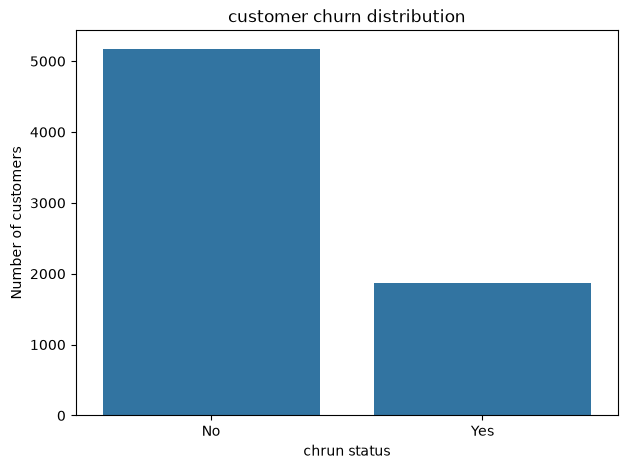

In [26]:
# visualizing the data

plt.figure(figsize=(7,5))
sns.countplot(data=df, x="Churn")

plt.title("customer churn distribution")
plt.xlabel("chrun status")
plt.ylabel("Number of customers")

plt.show()

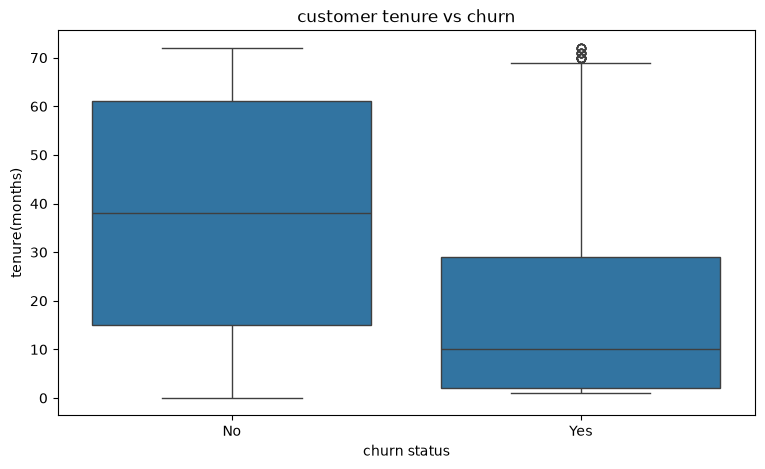

In [30]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    y="tenure",
    x="Churn",

)

plt.title("customer tenure vs churn")
plt.xlabel("churn status")
plt.ylabel("tenure(months)")

plt.show()

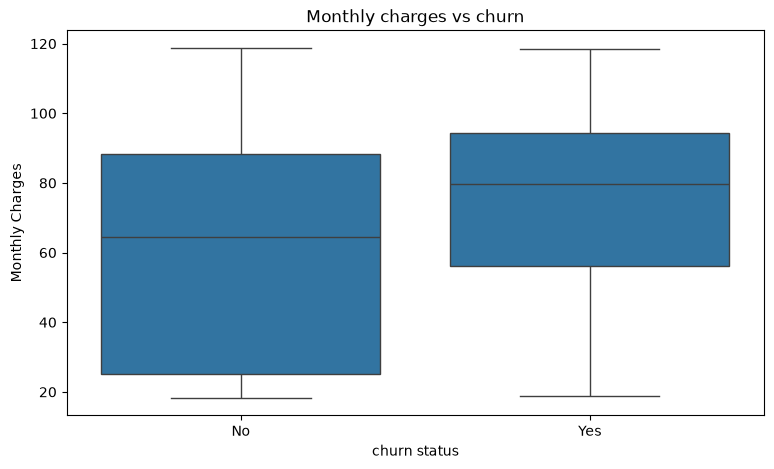

In [31]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly charges vs churn")
plt.xlabel("churn status")
plt.ylabel("Monthly Charges")

plt.show()

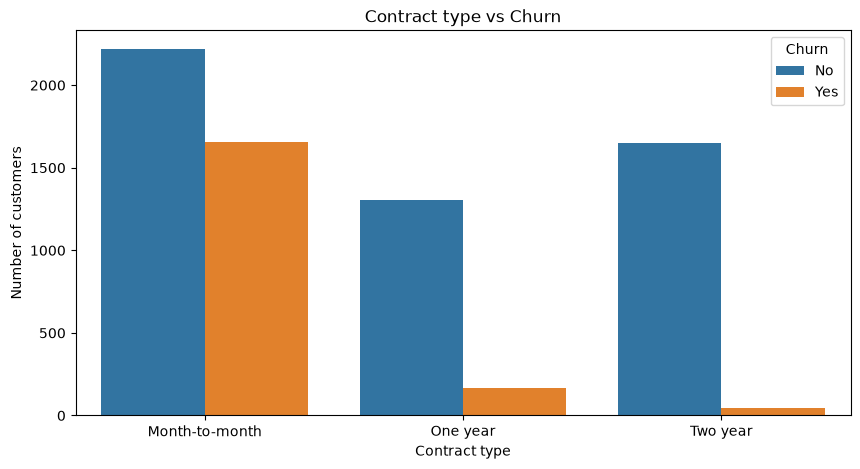

In [34]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract type vs Churn")
plt.xlabel("Contract type")
plt.ylabel("Number of customers")

plt.show()

In [35]:
contract_churn=pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
)* 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


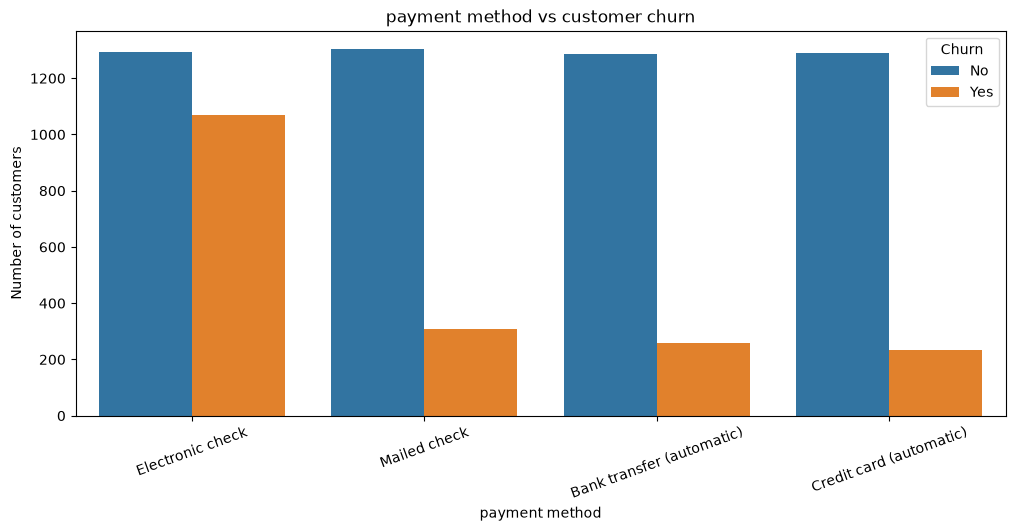

In [ ]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"

)

plt.title("payment method vs customer churn")
plt.xlabel("payment method")
plt.ylabel("Number of customers")
plt.xticks(rotation=20)   # rotates the x labels by 20 degrees for better visibility

plt.show()

In [42]:
payment_churn=pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
)*100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


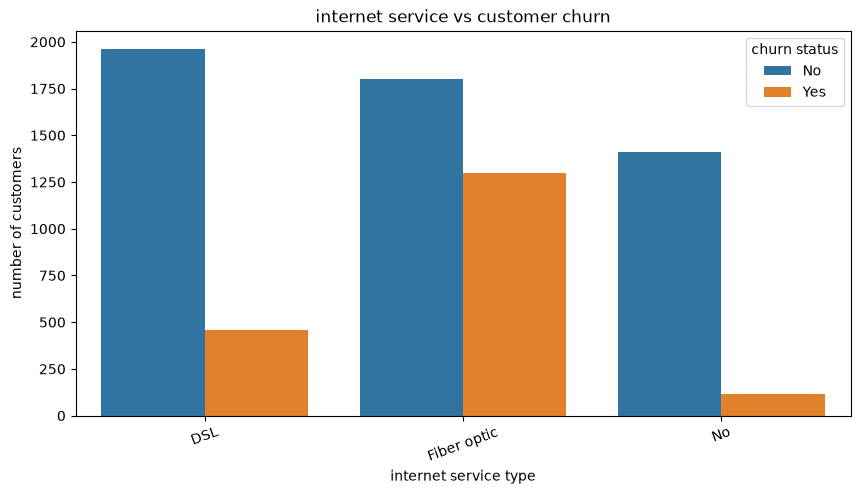

In [44]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("internet service vs customer churn")
plt.xlabel("internet service type")
plt.ylabel("number of customers")

plt.xticks(rotation=20)
plt.legend(title="churn status")

plt.show()

In [47]:
internet_service=pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
)*100

print(internet_service.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


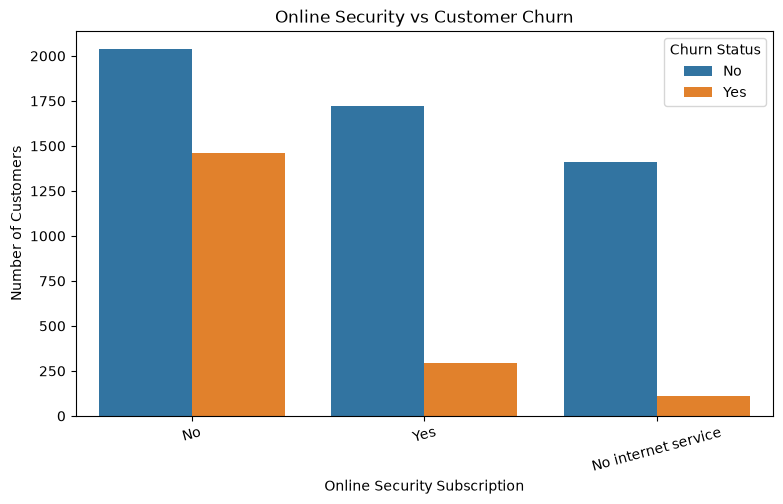

Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


In [49]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="OnlineSecurity",
    hue="Churn"
)

plt.title("Online Security vs Customer Churn")
plt.xlabel("Online Security Subscription")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.legend(title="Churn Status")

plt.show()

security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print(security_churn.round(2))

In [51]:
def churn_analysis(column):
    result=pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    )*100

    print(f"\nChurn Analysis:{column}")
    print(result.round(2))


churn_analysis("OnlineBackup")
churn_analysis("OnlineSecurity")
churn_analysis("TechSupport")




Churn Analysis:OnlineBackup
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53

Churn Analysis:OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

Churn Analysis:TechSupport
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


In [52]:
columns = [
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies"
]

for col in columns:
    churn_analysis(col)


Churn Analysis:DeviceProtection
Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50

Churn Analysis:StreamingTV
Churn                   No    Yes
StreamingTV                      
No                   66.48  33.52
No internet service  92.60   7.40
Yes                  69.93  30.07

Churn Analysis:StreamingMovies
Churn                   No    Yes
StreamingMovies                  
No                   66.32  33.68
No internet service  92.60   7.40
Yes                  70.06  29.94


In [ ]:
numerical_columns=[
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation=df[numerical_columns].corr()   # calculates correlation between the numerical columns

print(correlation.round(2))

                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


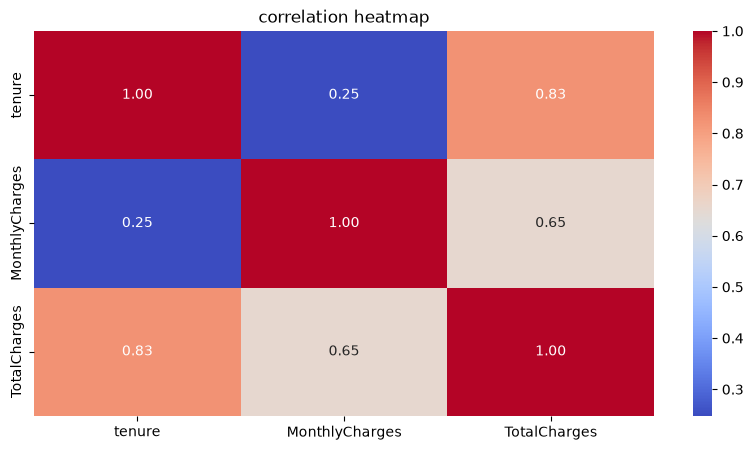

In [55]:
plt.figure(figsize=(10,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("correlation heatmap")

plt.show()